# Preprocessing Data
Membagi klip yang lolos audit ke data train dan test, mengubah audio jadi fitur Mel-Spectrogram + MFCC, lalu membuat data augmentation.

## 0. Setup

In [25]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import scipy.signal
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import Audio, display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110

In [26]:
OUT = Path("outputs")
SR, DUR = 16000, 6                 # 16 kHz, durasi target 6 detik
N_SAMPLES = SR * DUR               # 96.000 sampel
N_FFT, HOP, N_MELS, N_MFCC = 1024, 512, 64, 40
FMAX = 3500                        # batas atas Mel-Spectrogram (Hz)
SEED = 42
CLASSES = ["burping", "needs", "physical_pain", "scared"]
LABELS = {"burping": "Perlu sendawa", "needs": "Kebutuhan umum",
          "physical_pain": "Sakit fisik", "scared": "Kaget/takut"}

df = pd.read_csv(OUT / "metadata.csv")      # hasil Audit_Data
print(f"Hasil audit dimuat: {len(df)} klip, {(df.status == 'lolos').sum()} lolos")

Hasil audit dimuat: 4871 klip, 4240 lolos


## 1. Split data
Pakai `StratifiedGroupKFold` supaya proporsi kelas tetap sama dan klip dari satu rekaman tidak terpisah. Data test diambil 1 dari 7 bagian (sekitar 14%), sisanya dibagi jadi 5 fold. Seed 42.

In [27]:
data = df[df.status == "lolos"].reset_index(drop=True)
data["y"] = data.kelas.map(CLASSES.index)  # label kelas jadi angka 0-3
# ambil 1 dari 7 bagian sebagai test, satu grup tidak dipisah
_, te = next(StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(data, data.y, data.grup))
data["split"] = "train"; data.loc[te, "split"] = "test"
data["fold"] = -1  # -1 = data test
pool = data[data.split == "train"]
# sisa data dibagi jadi 5 fold
for k, (_, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(pool, pool.y, pool.grup)):
    data.loc[pool.index[va], "fold"] = k

# jumlah klip per kelas di tiap fold dan test
split_tab = pd.crosstab(data.kelas, data.split.where(data.split == "test", "fold " + data.fold.astype(str)), margins=True)
print(f"Test: {(data.split == 'test').mean():.1%} dari klip yang lolos audit")
split_tab

Test: 14.2% dari klip yang lolos audit


split,fold 0,fold 1,fold 2,fold 3,fold 4,test,All
kelas,,,,,,,
burping,31,51,31,30,31,24,198
needs,480,479,480,480,480,400,2799
physical_pain,96,95,96,96,96,80,559
scared,117,117,118,117,117,98,684
All,724,742,725,723,724,602,4240


## 2. Feature extraction
Setiap klip diubah jadi matriks 104 × 188 (64 baris Mel-Spectrogram + 40 baris MFCC, 188 frame).

### 2.1 Preprocessing audio
Urutannya: mono 16 kHz → high-pass filter 50 Hz → peak normalization → potong tengah kalau lebih dari 6 detik, zero padding kalau kurang. Hasilnya 96.000 sampel per klip.

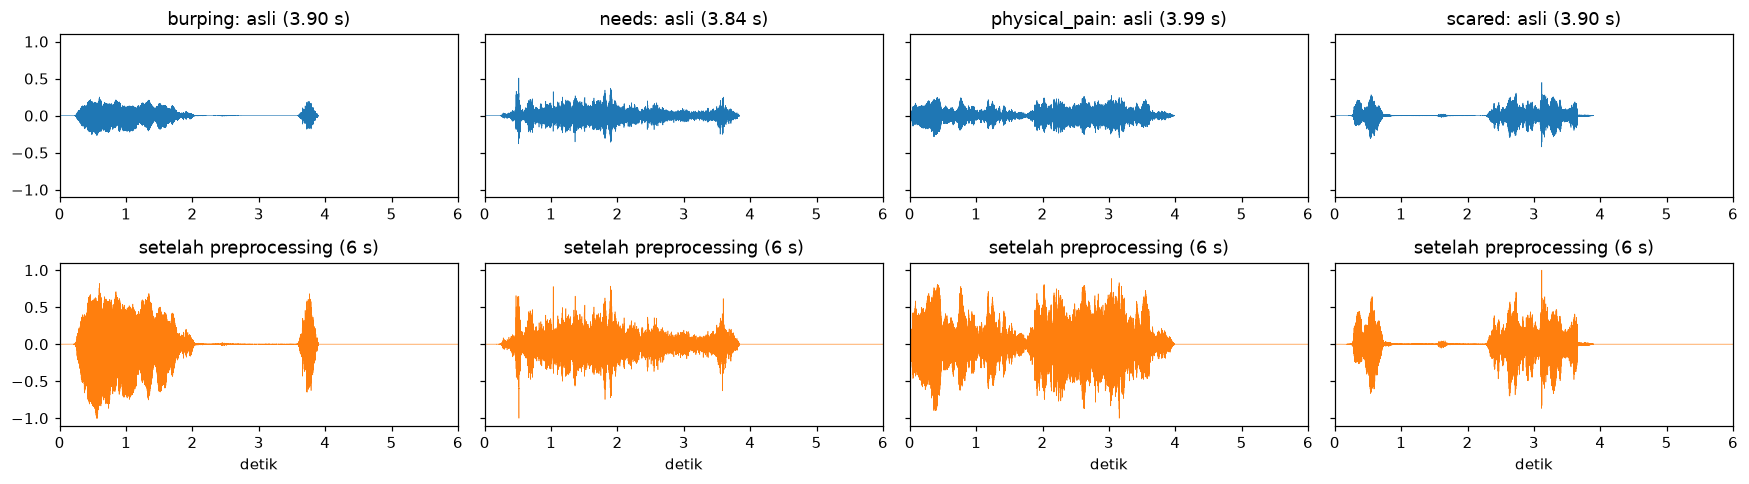

In [28]:
# high-pass filter orde 4, batas 50 Hz
HPF = scipy.signal.butter(4, 50, btype="highpass", fs=SR, output="sos")
EX = {k: data[data.kelas == k].path.iloc[0] for k in CLASSES}   # satu klip contoh per kelas

def load_audio(src):
    y, _ = librosa.load(src, sr=SR, mono=True)
    return y.astype(np.float32)

def preprocess(y):
    y = scipy.signal.sosfilt(HPF, y)  # buang noise frekuensi rendah (< 50 Hz)
    peak = np.max(np.abs(y)) if len(y) else 0.0
    if peak > 0:
        y = y / peak  # peak jadi 1
    if len(y) > N_SAMPLES:
        s = (len(y) - N_SAMPLES) // 2  # titik awal supaya potongan ada di tengah
        y = y[s:s + N_SAMPLES]
    else:
        y = np.pad(y, (0, N_SAMPLES - len(y)))  # tambah nol di akhir sampai 6 detik
    return y.astype(np.float32)

# cek: panjang selalu 96.000 sampel; peak tepat 1 untuk klip pendek, <= 1 untuk klip panjang
# (normalisasi sebelum dipotong, jadi peak bisa ada di bagian yang terbuang)
rng = np.random.default_rng(SEED)
pendek, panjang = preprocess(rng.standard_normal(SR * 2).astype(np.float32)), preprocess(rng.standard_normal(SR * 9).astype(np.float32))
assert len(pendek) == len(panjang) == N_SAMPLES
assert np.isclose(np.abs(pendek).max(), 1, atol=1e-3) and np.abs(panjang).max() <= 1 + 1e-6

fig, ax = plt.subplots(2, 4, figsize=(16, 4.5), sharey=True)
T = max(DUR, *(sf.info(p).duration for p in EX.values()))  # batas sumbu x ikut klip contoh terpanjang
for c, k in enumerate(CLASSES):
    y0 = load_audio(EX[k]); y1 = preprocess(y0)
    ax[0, c].plot(np.arange(len(y0)) / SR, y0, lw=.4); ax[0, c].set(title=f"{k}: asli ({len(y0) / SR:.2f} s)", xlim=(0, T))
    ax[1, c].plot(np.arange(len(y1)) / SR, y1, lw=.4, color="C1"); ax[1, c].set(title="setelah preprocessing (6 s)", xlim=(0, T), xlabel="detik")
fig.tight_layout(); fig.savefig(OUT / "fitur_1_preprocessing.png", bbox_inches="tight"); plt.show()

### 2.2 Mel-Spectrogram
n_fft 1024, hop 512, 64 Mel band dari 0 sampai 3,5 kHz, lalu diubah ke dB. 96.000 sampel jadi 188 frame.

Dibatasi 3,5 kHz karena banyak rekaman (terutama kelas needs) tidak punya frekuensi di atas sekitar 3,6 kHz. Kalau tidak dibatasi, model bisa menebak kelas dari bandwidth rekaman, bukan dari tangisannya.

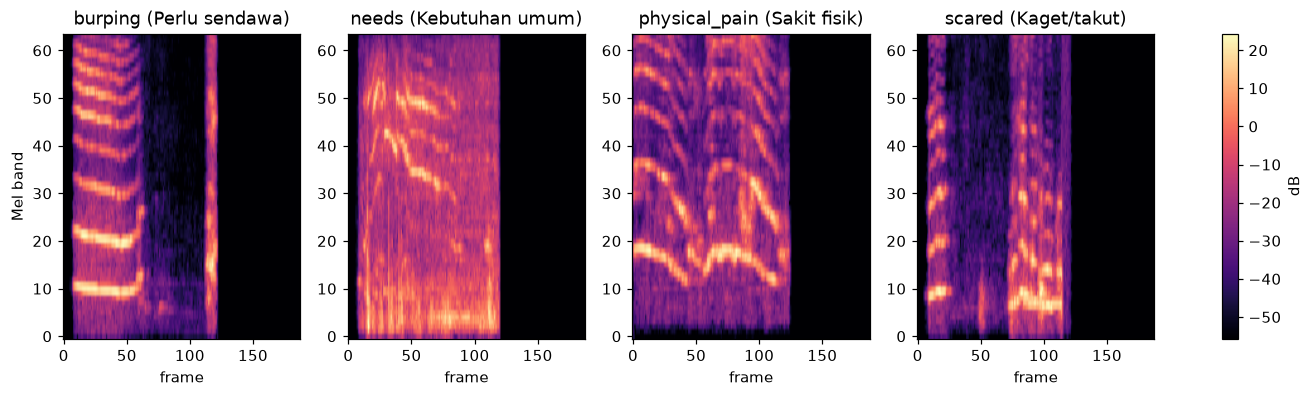

Ukuran Mel-Spectrogram: (64, 188)


In [29]:
def mel_db(y):
    return librosa.power_to_db(librosa.feature.melspectrogram(  # spektrum 64 Mel band (0-3,5 kHz), lalu diubah ke dB
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, fmax=FMAX, center=True), ref=1.0)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for c, k in enumerate(CLASSES):
    M = mel_db(preprocess(load_audio(EX[k])))
    im = ax[c].imshow(M, origin="lower", aspect="auto", cmap="magma")
    ax[c].set(title=f"{k} ({LABELS[k]})", xlabel="frame", ylabel="Mel band" if c == 0 else "")
fig.colorbar(im, ax=ax, label="dB"); fig.savefig(OUT / "fitur_2_mel.png", bbox_inches="tight"); plt.show()
print("Ukuran Mel-Spectrogram:", M.shape)

### 2.3 MFCC
40 koefisien MFCC dihitung dari Mel-Spectrogram di atas. Di gambar, tiap baris dinormalisasi supaya polanya kelihatan, tapi data yang disimpan tidak.

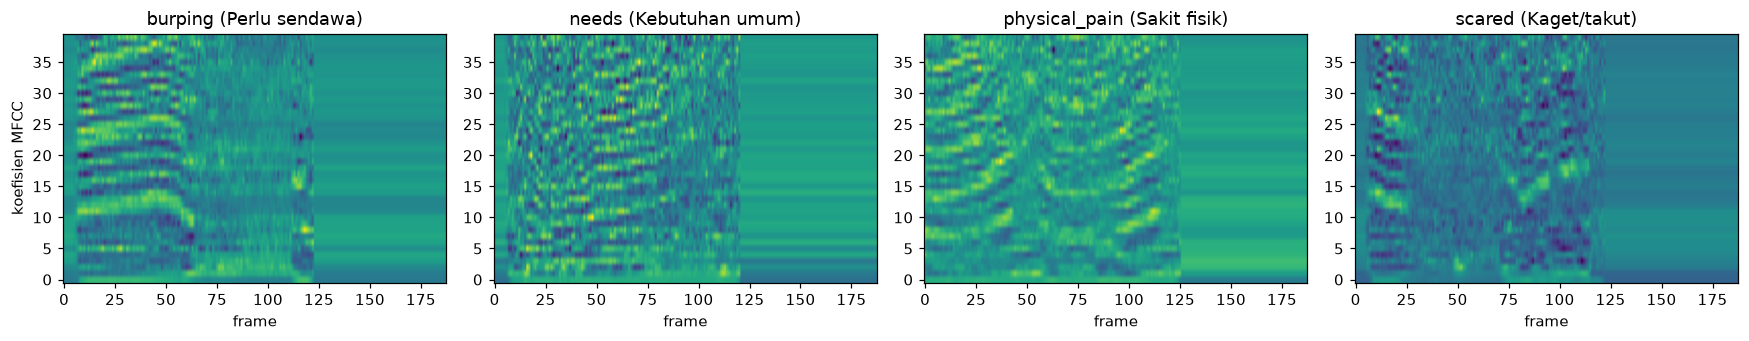

Ukuran MFCC: (40, 188)


In [30]:
def mfcc_of(M):
    return librosa.feature.mfcc(S=M, n_mfcc=N_MFCC)  # MFCC dihitung dari Mel-Spectrogram (dB)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for c, k in enumerate(CLASSES):
    C = mfcc_of(mel_db(preprocess(load_audio(EX[k]))))
    # normalisasi tiap baris, hanya untuk tampilan
    ax[c].imshow((C - C.mean(1, keepdims=True)) / (C.std(1, keepdims=True) + 1e-6), origin="lower", aspect="auto", cmap="viridis")
    ax[c].set(title=f"{k} ({LABELS[k]})", xlabel="frame", ylabel="koefisien MFCC" if c == 0 else "")
fig.tight_layout(); fig.savefig(OUT / "fitur_3_mfcc.png", bbox_inches="tight"); plt.show()
print("Ukuran MFCC:", C.shape)

### 2.4 Feature stacking
Mel (64) + MFCC (40) = 104 baris. Disimpan dalam float16 supaya filenya lebih kecil.

In [31]:
def extract_features(y):
    M = mel_db(y)
    return np.vstack([M, mfcc_of(M)]).astype(np.float32)  # tumpuk 64 baris Mel + 40 baris MFCC = 104 baris

f = extract_features(preprocess(load_audio(EX["needs"])))
assert f.shape == (104, 188), f.shape

# float16 supaya hemat memori
feat_clip = lambda p: extract_features(preprocess(load_audio(p))).astype(np.float16)
# ekstrak fitur semua klip secara paralel
X = np.stack(Parallel(n_jobs=-1, verbose=1)(delayed(feat_clip)(p) for p in data.path))
np.save(OUT / "X.npy", X)
print("X:", X.shape, X.dtype, "| semua nilai valid:", np.isfinite(X).all())

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    3.9s
[Parallel(n_jobs=-1)]: Done 920 tasks      | elapsed:    5.0s
[Parallel(n_jobs=-1)]: Done 4110 tasks      | elapsed:    7.7s
[Parallel(n_jobs=-1)]: Done 4240 out of 4240 | elapsed:    8.0s finished


X: (4240, 104, 188) float16 | semua nilai valid: True


## 3. Data augmentation
Setiap klip train dibuat satu salinan dengan salah satu teknik secara acak: pitch shift ±2 semitone, noise injection (SNR 20 dB), atau time stretch 0,9–1,1×. Augmentation dilakukan di audio, baru setelah itu diekstrak fiturnya. Data test tidak di-augment, dan salinan tetap masuk fold yang sama dengan klip aslinya.

In [32]:
def augment(y, seed, kind=None):
    rng = np.random.default_rng(seed)
    if kind is None:
        kind = int(rng.integers(3))  # pilih salah satu dari 3 teknik secara acak
    if kind == 0:
        y = librosa.effects.pitch_shift(y, sr=SR, n_steps=float(rng.uniform(-2, 2)))
    elif kind == 1:
        p = np.mean(y ** 2) + 1e-12  # power sinyal
        # tambah noise dengan SNR 20 dB
        y = y + rng.normal(0, np.sqrt(p / 10 ** (20 / 10)), len(y)).astype(np.float32)
    else:
        y = librosa.effects.time_stretch(y, rate=float(rng.uniform(0.9, 1.1)))
    return y, ["pitch_shift", "noise_injection", "time_stretch"][kind]

def feat_aug(path, seed):
    y, kind = augment(load_audio(path), seed)
    return extract_features(preprocess(y)).astype(np.float16), kind

train_df = data[data.split == "train"]
# seed beda tiap klip supaya hasilnya bisa diulang
res = Parallel(n_jobs=-1, verbose=1)(delayed(feat_aug)(p, SEED + i) for i, p in zip(train_df.index, train_df.path))
X_aug = np.stack([r[0] for r in res]); np.save(OUT / "X_aug.npy", X_aug)
# nomor baris X_aug milik tiap klip (-1 = tidak ada)
data["aug_row"] = -1; data.loc[train_df.index, "aug_row"] = np.arange(len(train_df))
data.loc[train_df.index, "aug_teknik"] = [r[1] for r in res]
data.to_csv(OUT / "data_siap.csv", index=False)
aug_counts = pd.Series([r[1] for r in res]).value_counts()
print("X_aug:", X_aug.shape, "| semua nilai valid:", np.isfinite(X_aug).all())
aug_counts.to_frame("jumlah_klip_train")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 856 tasks      | elapsed:    2.8s
[Parallel(n_jobs=-1)]: Done 2856 tasks      | elapsed:    7.5s
[Parallel(n_jobs=-1)]: Done 3638 out of 3638 | elapsed:    9.1s finished


X_aug: (3638, 104, 188) | semua nilai valid: True


,jumlah_klip_train
time_stretch,1253
noise_injection,1231
pitch_shift,1154


Contoh satu klip train: audio asli dibandingkan dengan hasil tiap teknik augmentation. Di Mel-Spectrogram, pitch shift menggeser pola harmonik naik atau turun, noise injection membuat latar belakang lebih terang karena ada noise, dan time stretch membuat pola jadi lebih panjang atau lebih pendek.

In [ ]:
y0 = load_audio(train_df.path.iloc[0])
teknik = ["pitch_shift", "noise_injection", "time_stretch"]
versi = {"asli": y0} | {t: augment(y0, SEED, kind=k)[0] for k, t in enumerate(teknik)}  # paksa tiap teknik sekali

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for c, (nama, y) in enumerate(versi.items()):
    display(Markdown(f"**{nama}** ({len(y) / SR:.2f} s)"), Audio(y, rate=SR))  # pemutar audio tiap versi
    ax[c].imshow(mel_db(preprocess(y)), origin="lower", aspect="auto", cmap="magma")
    ax[c].set(title=nama, xlabel="frame", ylabel="Mel band" if c == 0 else "")
fig.tight_layout(); fig.savefig(OUT / "fitur_4_augmentation.png", bbox_inches="tight"); plt.show()

## 4. Class weight
Dihitung dari data train saja, di sini contohnya untuk fold 0. Setiap klip train punya tepat satu salinan augmentation, jadi weight-nya sama dengan tanpa augmentation.

In [33]:
tr = data[(data.split == "train") & (data.fold != 0)]  # data train untuk fold 0 = fold 1-4
cnt = np.bincount(tr.y, minlength=4)
w = len(tr) / (4 * cnt)  # kelas yang sedikit dapat weight lebih besar
pd.DataFrame({"jumlah_train_fold0": cnt, "class_weight": w.round(2)}, index=CLASSES)

,jumlah_train_fold0,class_weight
burping,143,5.09
needs,1919,0.38
physical_pain,383,1.90
scared,469,1.55


## 5. Cek data leakage

In [34]:
te_set, tr_set = data[data.split == "test"], data[data.split == "train"]
# kalau salah satu cek gagal, data test sudah "bocor" ke train dan skor model jadi tidak bisa dipercaya
cek = {
    # tidak ada file yang isinya sama persis di seluruh data
    "Duplikat persis dibuang sebelum split": not data.hash.duplicated().any(),
    # potongan dari satu rekaman tidak boleh ada di train dan test sekaligus
    "Tidak ada potongan satu rekaman di train dan test": not set(te_set.grup) & set(tr_set.grup),
    # satu rekaman hanya boleh masuk ke satu fold
    "Tidak ada potongan satu rekaman di dua fold berbeda": (tr_set.groupby("grup").fold.nunique() == 1).all(),
    # test tidak punya salinan augmentation, semua klip train punya
    "Augmentation hanya dari data train": (te_set.aug_row == -1).all() and (tr_set.aug_row >= 0).all(),
}
hasil_cek = pd.DataFrame({"hasil": ["LULUS" if v else "GAGAL" for v in cek.values()]}, index=list(cek))
assert (hasil_cek.hasil == "LULUS").all()  # berhenti di sini kalau ada yang GAGAL
hasil_cek

,hasil
Duplikat persis dibuang sebelum split,LULUS
Tidak ada potongan satu rekaman di train dan test,LULUS
Tidak ada potongan satu rekaman di dua fold berbeda,LULUS
Augmentation hanya dari data train,LULUS
